# NB1 — Análisis estadístico de la corrida v4

Reproduce, paso a paso y con las mismas funciones, el análisis del capítulo 11 del informe (§11.1–§11.7): seis lotes (uno por escenario), 10 semillas por celda, 210 corridas. El cálculo de referencia es `experiments/analyze_lotes.py`, que escribe `airsim-runs/produccion/v4/analisis_lotes.md`. Este cuaderno **importa esas funciones** en lugar de reescribirlas, abre cada paso para mostrar qué calcula y verifica al final que sus tablas coinciden con las del reporte.

| Sección | Paso del análisis | Informe |
|---|---|---|
| §1 | Carga de los `summary.json` y recálculo de DistMin | §11.1 |
| §2 | Filtros de validez: versión de referencia por lote, ciclos mínimos, pilotos y descartes | §10.12.2, §11.1 |
| §3 | SPL: definición y cálculo | §10.6.1 |
| §4 | Tabla por celda: éxito con IC de Wilson, SPL, tiempo y distancia mínima | §11.2 |
| §5 | Una comparación abierta: delta de Cliff, IC *bootstrap*, permutación exacta, Bonferroni | §10.7 |
| §6 | Las 18 comparaciones planificadas y su lectura | §11.3, §11.4 |
| §7 | Secundarias: Fisher, Newcombe y distancia mínima | §11.3, §11.4 |
| §8 | H2: razón de tiempos frente a la longitud de la ruta | §11.7 |
| §9 | Ritmo del lazo y latencias por celda | §11.6 |
| §10 | Verificación contra `analisis_lotes.md` y exportación | — |

**Diseño (cap. 10).** Lotes de control (A `minisim_clear`, B `townsim_clear`, C `citysim_clear`) con tres celdas: `slm x depth`, `fsm x depth` y `reactive`. Lotes con obstrucción (D `townsim_ini`, E `townsim_calib_cruce_frontal`, F `citysim_pilot`) con cuatro: se agrega `fsm x blind`. Métrica primaria: tiempo de las misiones exitosas en A–C y SPL en D–F.

## §0 — Configuración

In [1]:
import os, sys, json, math, glob, itertools, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import rankdata, norm
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / 'config' / '.env').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
LOOP = ROOT / 'airsim-loop'
sys.path.insert(0, str(LOOP / 'experiments'))
import analyze_lotes as AL
from analyze import load_optimal_lengths, spl

V4 = ROOT / 'airsim-runs' / 'produccion' / 'v4'
MISSIONS = ROOT / 'airsim-plan' / 'missions' / 'flightplans'
OUT = LOOP / 'notebooks' / 'output'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 200)
CELDAS = AL.CELL_ORDER
PALETA = {'slm x depth': '#1f77b4', 'fsm x depth': '#ff7f0e', 'fsm x blind': '#d62728', 'reactive': '#2ca02c'}
NOMBRE_LOTE = {v: k for k, v in AL.LOTES.items()}
print('lotes:', AL.LOTES)
print('obstruccion:', sorted(AL.OBSTRUCTED), '| alfa =', AL.ALPHA, '| ciclos minimos =', AL.MIN_VALID_CYCLES)

lotes: {'minisim_clear': 'A', 'townsim_clear': 'B', 'citysim_clear': 'C', 'townsim_ini': 'D', 'townsim_calib_cruce_frontal': 'E', 'citysim_pilot': 'F'}
obstruccion: ['D', 'E', 'F'] | alfa = 0.05 | ciclos minimos = 50


## §1 — Carga

`load_runs()` recorre `v4/**/*.summary.json` y salta `pilotos/` y `descarte/`: los pilotos con semilla 99 y las corridas apartadas por un error de armado, con su motivo en `DESCARTE.md`. Cuando existe la auditoría `<corrida>.distmin.ndjson`, recalcula la distancia mínima **sin la primera muestra**, que es un artefacto del arranque. El valor original queda en `min_obstacle_dist_m_raw`.

In [2]:
runs = AL.load_runs(str(V4))
df = pd.DataFrame(runs)
df['celda'] = [AL.cell_label(r) for r in runs]
df['lote'] = df['scenario'].map(AL.LOTES)
print(f'{len(df)} corridas leidas (sin pilotos/ ni descarte/)')
display(pd.crosstab([df['lote'], df['scenario']], df['celda'])[CELDAS])
cambio = df[df['min_obstacle_dist_m_raw'].notna() & (df['min_obstacle_dist_m_raw'] != df['min_obstacle_dist_m'])]
print(f'corridas en que DistMin cambia al quitar la primera muestra: {len(cambio)}')
display(cambio[['lote', 'celda', 'seed', 'min_obstacle_dist_m_raw', 'min_obstacle_dist_m']].head())

210 corridas leidas (sin pilotos/ ni descarte/)


,celda,slm x depth,fsm x depth,fsm x blind,reactive
lote,scenario,,,,
A,minisim_clear,10,10,0,10
B,townsim_clear,10,10,0,10
C,citysim_clear,10,10,0,10
D,townsim_ini,10,10,10,10
E,townsim_calib_cruce_frontal,10,10,10,10
F,citysim_pilot,10,10,10,10


corridas en que DistMin cambia al quitar la primera muestra: 45


,lote,celda,seed,min_obstacle_dist_m_raw,min_obstacle_dist_m
0,A,fsm x depth,11,12.713,15.500
1,A,fsm x depth,13,12.674,15.665
2,A,fsm x depth,17,12.721,15.438
3,A,fsm x depth,19,12.713,15.485
4,A,fsm x depth,23,12.666,15.430


## §2 — Filtros de validez

Cada lote se corrió de una vez con un solo `code_version`. La versión de referencia de un lote es la versión limpia más frecuente dentro de su escenario; el código de vuelo es idéntico en todas, y entre ellas cambian el runner y el lanzador. Una corrida se descarta si su versión difiere de la de su lote, si termina en `-dirty` (cambios sin confirmar), si tiene menos de 50 ciclos (falla de infraestructura) o si su semilla no está en la lista declarada.

In [3]:
ref = AL.reference_versions(runs)
display(pd.DataFrame([{'lote': AL.LOTES[s], 'escenario': s, 'version de referencia': v,
                       'versiones presentes': dict(collections.Counter(r['code_version'] for r in runs if r['scenario'] == s))}
                      for s, v in sorted(ref.items(), key=lambda kv: AL.LOTES[kv[0]])]))
kept, dropped = AL.filter_runs(runs, ref)
print(f'validas: {len(kept)}; descartadas: {len(dropped)}')
for r, motivo in dropped:
    print('  ', r['_path'], '->', motivo)
dv = pd.DataFrame(kept)
dv['celda'] = [AL.cell_label(r) for r in kept]
dv['lote'] = dv['scenario'].map(AL.LOTES)
print('ciclos por corrida: min', dv['cycles'].min(), '| mediana', int(dv['cycles'].median()), '| max', dv['cycles'].max())
print('colisiones registradas por la bandera de AirSim:', int(dv['collisions'].sum()))

,lote,escenario,version de referencia,versiones presentes
0,A,minisim_clear,b0332e1a,{'b0332e1a': 30}
1,B,townsim_clear,12e90aab,{'12e90aab': 30}
2,C,citysim_clear,7053f405,{'7053f405': 30}
3,D,townsim_ini,835ae75f,{'835ae75f': 40}
4,E,townsim_calib_cruce_frontal,835ae75f,{'835ae75f': 40}
5,F,citysim_pilot,55583639,{'55583639': 40}


validas: 210; descartadas: 0
ciclos por corrida: min 330 | mediana 1889 | max 4951
colisiones registradas por la bandera de AirSim: 0


## §3 — SPL (*Success weighted by Path Length*)

$$\text{SPL} = S \cdot \frac{L_\text{opt}}{\max(L_\text{recorrida},\ L_\text{opt})}$$

con $S \in \{0, 1\}$ el éxito de la corrida (Anderson et al., 2018). $L_\text{opt}$ es la suma de las distancias 3D entre waypoints consecutivos **del manifiesto**, sin el tramo desde el *spawn*. Penaliza tanto no llegar (SPL = 0) como llegar dando vueltas.

En los lotes D, E y F los cuatro brazos vuelan además los puntos de paso del plan de ruta (NB4), así que su SPL queda por debajo de 1 aun con la ruta perfecta. El sesgo es igual para todas las celdas de un lote, y por eso el SPL se compara solo **dentro** de cada lote.

In [4]:
L_opt = load_optimal_lengths(str(MISSIONS))
display(pd.DataFrame([{'lote': AL.LOTES[s], 'escenario': s, 'L_opt (m)': round(L_opt[s], 1),
                       'waypoints': len(json.loads((MISSIONS / f'{s}.json').read_text(encoding='utf-8'))['waypoints'])}
                      for s in sorted(AL.LOTES, key=AL.LOTES.get)]))
dv['spl'] = [spl(r, L_opt) for r in kept]

# Ejemplo trabajado: una corrida exitosa y una fallida
for _, r in dv[dv['lote'] == 'F'].sort_values('success').iloc[[0, -1]].iterrows():
    lo = L_opt[r['scenario']]
    print(f"{r['celda']:<12} semilla {r['seed']}: exito={r['success']}, L_recorrida={r['path_length_m']:.1f} m, "
          f"L_opt={lo:.1f} m -> SPL = {int(r['success'])} x {lo:.1f}/max({r['path_length_m']:.1f}, {lo:.1f}) = {r['spl']:.3f}")

,lote,escenario,L_opt (m),waypoints
0,A,minisim_clear,120.0,3
1,B,townsim_clear,587.7,6
2,C,citysim_clear,345.2,4
3,D,townsim_ini,312.5,8
4,E,townsim_calib_cruce_frontal,320.0,4
5,F,citysim_pilot,338.8,8


fsm x depth  semilla 233: exito=False, L_recorrida=474.1 m, L_opt=338.8 m -> SPL = 0 x 338.8/max(474.1, 338.8) = 0.000
slm x depth  semilla 281: exito=True, L_recorrida=755.8 m, L_opt=338.8 m -> SPL = 1 x 338.8/max(755.8, 338.8) = 0.448


## §4 — Resultados por celda (§11.2)

**Éxito con IC de Wilson 95 %.** Con $\hat p = k/n$ y $z = 1.96$:

$$\text{centro} = \frac{\hat p + z^2/2n}{1 + z^2/n}, \qquad \text{semiancho} = \frac{z\sqrt{\hat p(1-\hat p)/n + z^2/4n^2}}{1 + z^2/n}$$

A diferencia del intervalo de Wald, no colapsa en 0/n ni en n/n: con 10/10 el IC es [0.72, 1.00], no [1, 1]. Las métricas continuas se informan como mediana [p25, p75]. Con 10 corridas por celda y distribuciones asimétricas, sobre todo el SPL con ceros por las fallas, la media y el desvío estándar no describen bien la celda.

In [5]:
k, n = 9, 10
p, z = k / n, norm.ppf(0.975)
den = 1 + z * z / n
centro = (p + z * z / (2 * n)) / den
semi = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
print(f'Wilson a mano para 9/10: [{centro - semi:.3f}, {centro + semi:.3f}]  |  AL.wilson: {tuple(round(v, 3) for v in AL.wilson(k, n))}')
print(f'Wald para 9/10 (no usado): [{p - z * math.sqrt(p * (1 - p) / n):.3f}, {p + z * math.sqrt(p * (1 - p) / n):.3f}]')

res = AL.analyze(kept, L_opt, n_boot=5000, family=18)
cells = pd.DataFrame(res['cells'])
display(cells[['lote', 'escenario', 'celda', 'n', 'exitos', 'wilson_lo', 'wilson_hi', 'spl', 'tiempo_exito_s', 'dist_min_m', 'colisiones']]
        .round({'wilson_lo': 2, 'wilson_hi': 2}))

Wilson a mano para 9/10: [0.596, 0.982]  |  AL.wilson: (np.float64(0.596), np.float64(0.982))
Wald para 9/10 (no usado): [0.714, 1.086]


,lote,escenario,celda,n,exitos,wilson_lo,wilson_hi,spl,tiempo_exito_s,dist_min_m,colisiones
0,A,minisim_clear,slm x depth,10,10,0.72,1.00,"0.54 [0.51, 0.56]","165.07 [159.78, 171.41]","15.51 [15.47, 15.64]",0
1,A,minisim_clear,fsm x depth,10,10,0.72,1.00,"0.38 [0.35, 0.43]","306.40 [252.85, 369.46]","15.49 [15.44, 15.63]",0
2,A,minisim_clear,reactive,10,10,0.72,1.00,"0.63 [0.63, 0.63]","84.85 [84.69, 85.26]","15.47 [15.46, 15.50]",0
3,B,townsim_clear,slm x depth,10,10,0.72,1.00,"0.89 [0.87, 0.90]","379.77 [366.41, 399.07]","16.41 [12.43, 16.48]",0
4,B,townsim_clear,fsm x depth,10,9,0.60,0.98,"0.76 [0.72, 0.80]","488.62 [434.08, 516.18]","1.55 [0.24, 3.63]",0
5,B,townsim_clear,reactive,10,10,0.72,1.00,"0.93 [0.91, 0.93]","272.60 [272.42, 280.77]","14.77 [7.89, 16.68]",0
6,C,citysim_clear,slm x depth,10,9,0.60,0.98,"0.70 [0.68, 0.72]","286.24 [277.14, 288.93]","11.45 [10.38, 12.50]",0
7,C,citysim_clear,fsm x depth,10,6,0.31,0.83,"0.42 [0.00, 0.43]","705.94 [664.78, 748.85]","0.10 [0.10, 0.11]",0
8,C,citysim_clear,reactive,10,10,0.72,1.00,"0.79 [0.79, 0.79]","192.28 [190.64, 194.08]","10.85 [10.70, 10.97]",0
9,D,townsim_ini,slm x depth,10,9,0.60,0.98,"0.48 [0.43, 0.48]","519.87 [517.88, 524.34]","0.13 [0.11, 0.37]",0


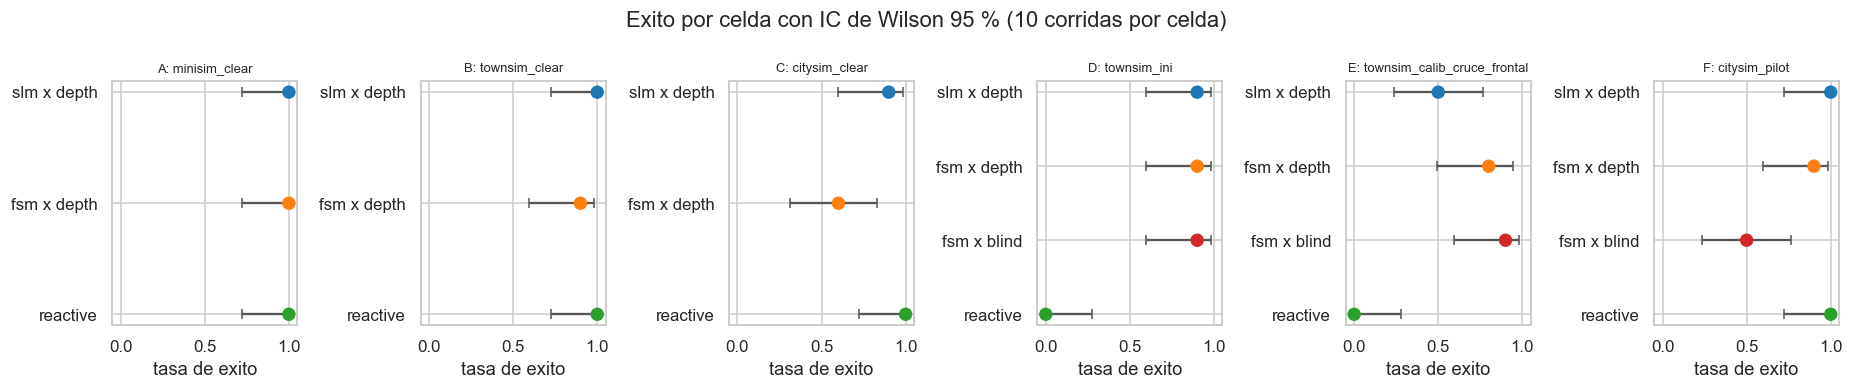

In [6]:
fig, axes = plt.subplots(1, 6, figsize=(17, 3.6))
for ax, lote in zip(axes, sorted(AL.LOTES.values())):
    c = cells[cells['lote'] == lote].set_index('celda').reindex([x for x in CELDAS if x in set(cells[cells['lote'] == lote]['celda'])])
    y = np.arange(len(c))
    ax.errorbar(c['tasa'], y, xerr=[(c['tasa'] - c['wilson_lo']).clip(lower=0), (c['wilson_hi'] - c['tasa']).clip(lower=0)], fmt='none', ecolor='#555', capsize=3)
    ax.scatter(c['tasa'], y, c=[PALETA[i] for i in c.index], s=60, zorder=3)
    ax.set_yticks(y, c.index); ax.set_xlim(-0.05, 1.05); ax.invert_yaxis()
    ax.set_title(f"{lote}: {NOMBRE_LOTE[lote]}", fontsize=8.5); ax.set_xlabel('tasa de exito')
fig.suptitle('Exito por celda con IC de Wilson 95 % (10 corridas por celda)')
plt.tight_layout(); fig.savefig(FIG / 'v4_exito_wilson.png', dpi=150); plt.show()

C:\Users\Jenic\AppData\Local\Temp\ipykernel_31224\2575683751.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=e, x='celda', y='duration_s', order=orden, palette=PALETA, ax=ax, width=0.5, showfliers=False)
C:\Users\Jenic\AppData\Local\Temp\ipykernel_31224\2575683751.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=e, x='celda', y='duration_s', order=orden, palette=PALETA, ax=ax, width=0.5, showfliers=False)
C:\Users\Jenic\AppData\Local\Temp\ipykernel_31224\2575683751.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=

C:\Users\Jenic\AppData\Local\Temp\ipykernel_31224\2575683751.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d, x='celda', y='spl', order=orden, palette=PALETA, ax=ax, width=0.5, showfliers=False)


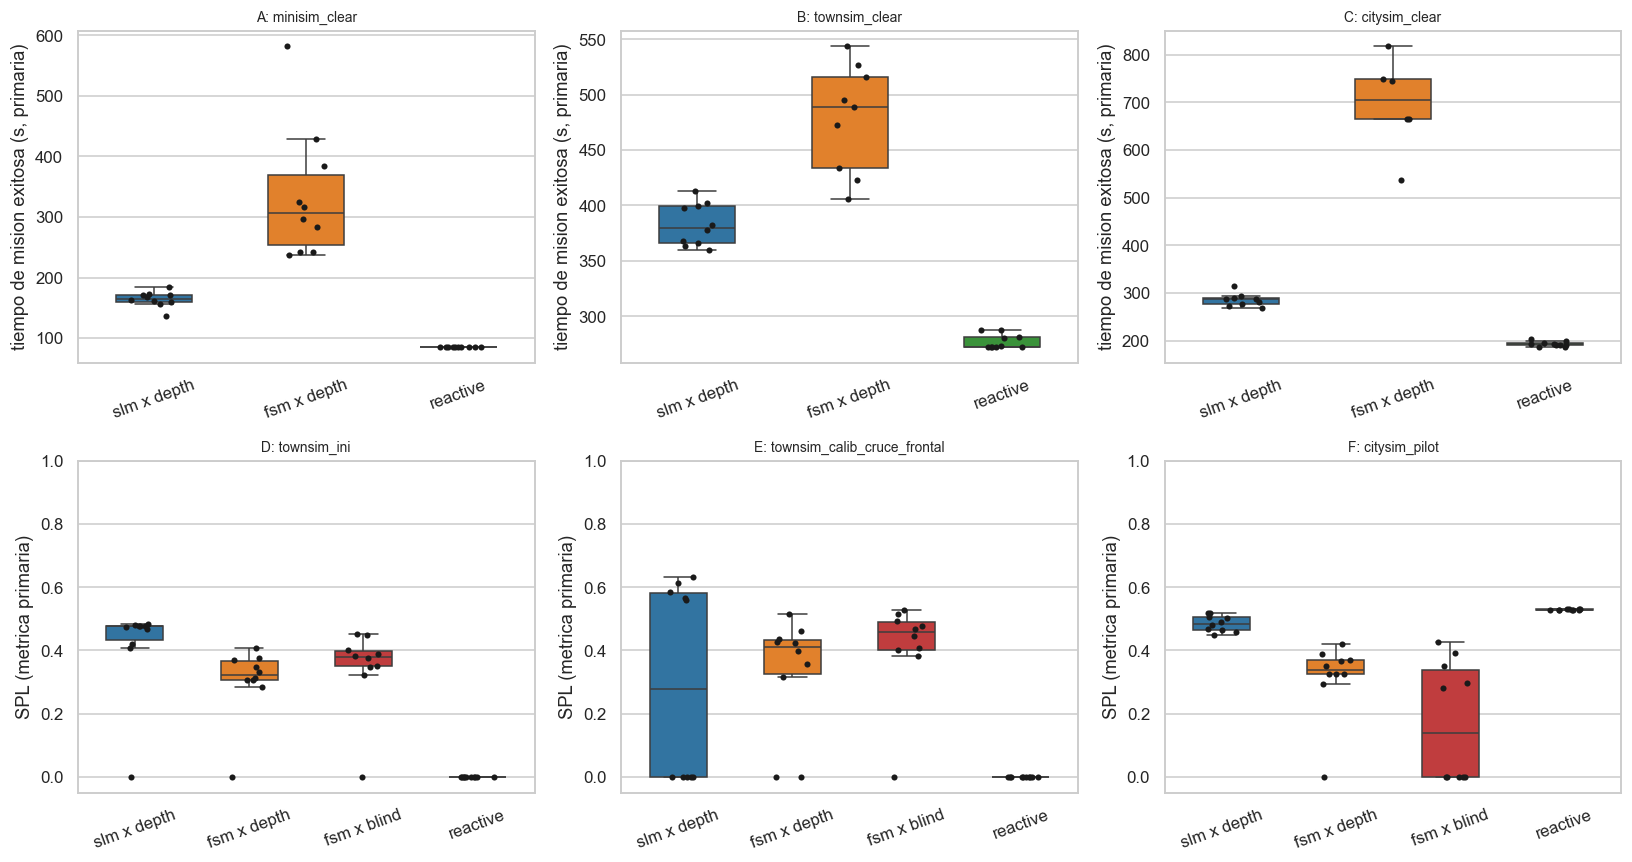

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, lote in zip(axes.flat, sorted(AL.LOTES.values())):
    d = dv[dv['lote'] == lote]
    orden = [c for c in CELDAS if c in set(d['celda'])]
    if lote in AL.OBSTRUCTED:
        sns.boxplot(data=d, x='celda', y='spl', order=orden, palette=PALETA, ax=ax, width=0.5, showfliers=False)
        sns.stripplot(data=d, x='celda', y='spl', order=orden, color='k', size=4, jitter=0.15, ax=ax)
        ax.set_ylabel('SPL (metrica primaria)'); ax.set_ylim(-0.05, 1)
    else:
        e = d[d['success']]
        sns.boxplot(data=e, x='celda', y='duration_s', order=orden, palette=PALETA, ax=ax, width=0.5, showfliers=False)
        sns.stripplot(data=e, x='celda', y='duration_s', order=orden, color='k', size=4, jitter=0.15, ax=ax)
        ax.set_ylabel('tiempo de mision exitosa (s, primaria)')
    ax.set_title(f'{lote}: {NOMBRE_LOTE[lote]}', fontsize=9); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); fig.savefig(FIG / 'v4_metrica_primaria.png', dpi=150); plt.show()

## §5 — Una comparación abierta paso a paso

Se toma la comparación (iii) del lote D: `slm x depth` frente a `fsm x depth`, con SPL como métrica. Hay tres piezas.

1. **Delta de Cliff.** $\delta = P(X > Y) - P(X < Y)$, el promedio del signo de las $n_a \times n_b$ diferencias por pares. Va de −1 a +1, no supone normalidad y admite empates (frecuentes en SPL: todas las fallas valen 0). Umbrales usuales (Romano et al., 2006): |δ| < 0.147 despreciable, < 0.33 pequeño, < 0.474 mediano, y grande por encima.
2. **IC 95 % por *bootstrap***: se remuestrean corridas **dentro de cada celda** 5000 veces y se toman los percentiles 2.5 y 97.5 del δ.
3. **Prueba de permutación exacta sobre los rangos**: es Mann-Whitney exacto con rangos medios para los empates. Con 10 + 10 corridas hay $\binom{20}{10} = 184\,756$ formas de repartir las etiquetas. El *p* bilateral es la fracción de repartos con una diferencia de rangos medios al menos tan extrema como la observada.

SPL:
  slm x depth: [0.    0.409 0.422 0.467 0.475 0.477 0.477 0.477 0.48  0.485]
  fsm x depth: [0.    0.285 0.308 0.308 0.311 0.331 0.349 0.371 0.377 0.408]

pares: 100; X>Y: 90, X<Y: 9, empates: 1  ->  delta = +0.810  (AL.cliffs_delta: +0.810)


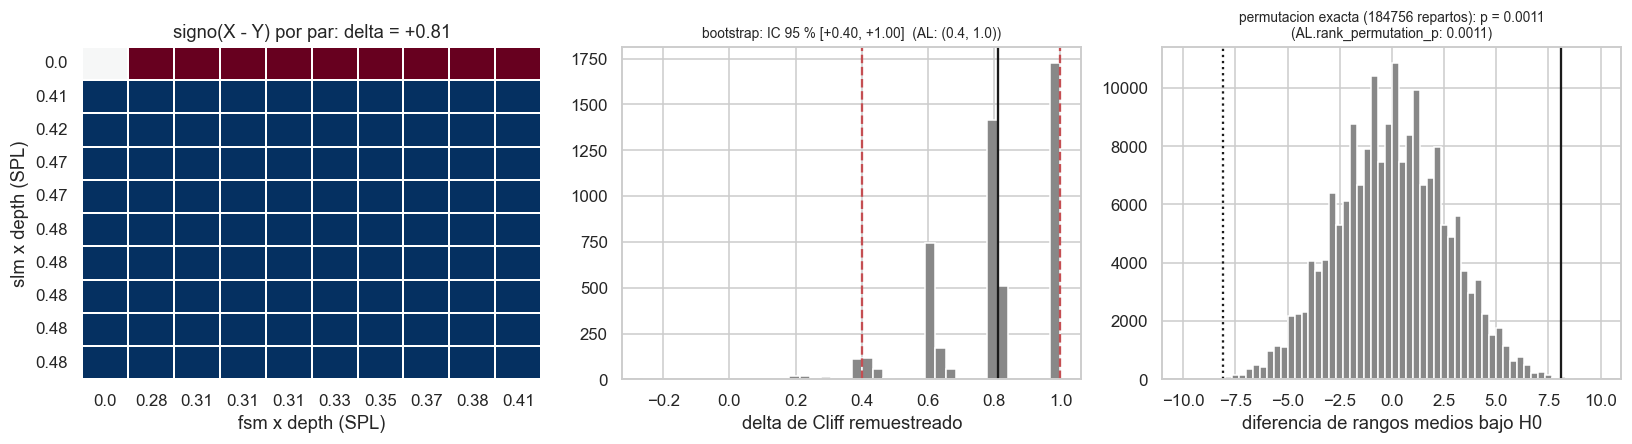

Bonferroni: familia de 18 comparaciones (3 por lote x 6 lotes) -> alfa corregido = 0.05/18 = 0.0028; p x 18 = 0.0191 -> significativa
p minimo posible con 10 + 10: 2/184756 = 1.08e-05; con 5 + 5 seria 2/252 = 0.0079 (> alfa corregido)


In [8]:
LOTE, A, B = 'D', 'slm x depth', 'fsm x depth'
ra = [r for r in kept if AL.LOTES[r['scenario']] == LOTE and AL.cell_label(r) == A]
rb = [r for r in kept if AL.LOTES[r['scenario']] == LOTE and AL.cell_label(r) == B]
metrica, xa = AL.primary_values(ra, LOTE, L_opt)
_, xb = AL.primary_values(rb, LOTE, L_opt)
xa, xb = np.array(sorted(xa)), np.array(sorted(xb))
print(f'{metrica}:\n  {A}: {np.round(xa, 3)}\n  {B}: {np.round(xb, 3)}')

S = np.sign(xa[:, None] - xb[None, :])
delta = S.mean()
print(f'\npares: {S.size}; X>Y: {(S > 0).sum()}, X<Y: {(S < 0).sum()}, empates: {(S == 0).sum()}  ->  delta = {delta:+.3f}  (AL.cliffs_delta: {AL.cliffs_delta(xa, xb):+.3f})')

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
sns.heatmap(S, cmap='RdBu', center=0, cbar=False, ax=ax[0], xticklabels=np.round(xb, 2), yticklabels=np.round(xa, 2), linewidths=0.3)
ax[0].tick_params(axis='y', rotation=0); ax[0].set_xlabel(f'{B} (SPL)'); ax[0].set_ylabel(f'{A} (SPL)'); ax[0].set_title(f'signo(X - Y) por par: delta = {delta:+.2f}')

rng = np.random.default_rng(0)
xbt = xa[rng.integers(0, len(xa), (5000, len(xa)))]; ybt = xb[rng.integers(0, len(xb), (5000, len(xb)))]
deltas = np.sign(xbt[:, :, None] - ybt[:, None, :]).mean(axis=(1, 2))
lo, hi = np.quantile(deltas, [0.025, 0.975])
ax[1].hist(deltas, bins=40, color='#888'); ax[1].axvline(delta, color='k'); ax[1].axvline(lo, color='r', ls='--'); ax[1].axvline(hi, color='r', ls='--')
ax[1].set_title(f'bootstrap: IC 95 % [{lo:+.2f}, {hi:+.2f}]  (AL: {tuple(round(v, 2) for v in AL.cliffs_delta_ci(xa, xb))})', fontsize=9)
ax[1].set_xlabel('delta de Cliff remuestreado')

ranks = rankdata(np.concatenate([xa, xb]))
obs = ranks[:10].mean() - ranks[10:].mean()
null = np.array([ranks[list(c)].mean() - np.delete(ranks, list(c)).mean() for c in itertools.combinations(range(20), 10)])
p_exact = np.mean(np.abs(null) >= abs(obs) - 1e-12)
ax[2].hist(null, bins=60, color='#888'); ax[2].axvline(obs, color='k'); ax[2].axvline(-obs, color='k', ls=':')
ax[2].set_title(f'permutacion exacta ({len(null)} repartos): p = {p_exact:.4f}\n(AL.rank_permutation_p: {AL.rank_permutation_p(xa, xb):.4f})', fontsize=9)
ax[2].set_xlabel('diferencia de rangos medios bajo H0')
plt.tight_layout(); plt.show()

fam = 18
print(f'Bonferroni: familia de {fam} comparaciones (3 por lote x 6 lotes) -> alfa corregido = 0.05/{fam} = {0.05 / fam:.4f}; '
      f'p x {fam} = {min(1, p_exact * fam):.4f} -> {"significativa" if p_exact < 0.05 / fam else "no significativa"}')
print(f'p minimo posible con 10 + 10: 2/{len(null)} = {2 / len(null):.2e}; con 5 + 5 seria 2/252 = {2 / 252:.4f} (> alfa corregido)')

La última línea explica por qué el diseño pasó a 10 semillas por celda. Con 5 + 5 corridas el *p* mínimo alcanzable (0.0079) queda por encima del alfa corregido (0.0028): ninguna comparación podría resultar significativa, por grande que fuera el efecto.

## §6 — Las 18 comparaciones planificadas

Tres por lote, fijadas antes de correr (cap. 10 §10.12.2):

- **Controles (A, B, C)**, con el tiempo de misión exitosa: `slm–fsm`, `slm–reactive` y `fsm–reactive`.
- **Obstrucción (D, E, F)**, con el SPL:
  - (i) `slm x depth` vs `fsm x blind`: el sistema completo frente a una FSM sin barrido;
  - (ii) `fsm x depth` vs `fsm x blind`: el aporte del barrido con profundidad;
  - (iii) `slm x depth` vs `fsm x depth`: el aporte de la capa estratégica y la política del brazo `slm`.

**Signo de δ.** δ > 0 indica que la primera celda tiene valores mayores. En SPL eso es mejor, y en tiempo, peor (tarda más).

In [9]:
comps = pd.DataFrame(res['comparisons'])
print(f"familia = {res['family']}; alfa corregido = {res['alpha_corr']:.4f}; significativas: {comps['significativa'].sum()} de {len(comps)}")
display(comps[['lote', 'comparacion', 'a', 'b', 'metrica_primaria', 'n_a', 'n_b', 'cliff', 'cliff_lo', 'cliff_hi', 'p', 'p_bonf', 'significativa']]
        .round({'cliff': 2, 'cliff_lo': 2, 'cliff_hi': 2}))

familia = 18; alfa corregido = 0.0028; significativas: 12 de 18


,lote,comparacion,a,b,metrica_primaria,n_a,n_b,cliff,cliff_lo,cliff_hi,p,p_bonf,significativa
0,A,slm-fsm,slm x depth,fsm x depth,tiempo de mision exitosa (s),10,10,-1.00,-1.00,-1.00,0.000011,0.000195,True
1,A,slm-reactive,slm x depth,reactive,tiempo de mision exitosa (s),10,10,1.00,1.00,1.00,0.000011,0.000195,True
2,A,fsm-reactive,fsm x depth,reactive,tiempo de mision exitosa (s),10,10,1.00,1.00,1.00,0.000011,0.000195,True
3,B,slm-fsm,slm x depth,fsm x depth,tiempo de mision exitosa (s),10,9,-0.98,-1.00,-0.87,0.000043,0.000779,True
4,B,slm-reactive,slm x depth,reactive,tiempo de mision exitosa (s),10,10,1.00,1.00,1.00,0.000011,0.000195,True
5,B,fsm-reactive,fsm x depth,reactive,tiempo de mision exitosa (s),9,10,1.00,1.00,1.00,0.000022,0.000390,True
6,C,slm-fsm,slm x depth,fsm x depth,tiempo de mision exitosa (s),9,6,-1.00,-1.00,-1.00,0.000400,0.007193,True
7,C,slm-reactive,slm x depth,reactive,tiempo de mision exitosa (s),9,10,1.00,1.00,1.00,0.000022,0.000390,True
8,C,fsm-reactive,fsm x depth,reactive,tiempo de mision exitosa (s),6,10,1.00,1.00,1.00,0.000250,0.004496,True
9,D,i,slm x depth,fsm x blind,SPL,10,10,0.73,0.28,1.00,0.003940,0.070926,False


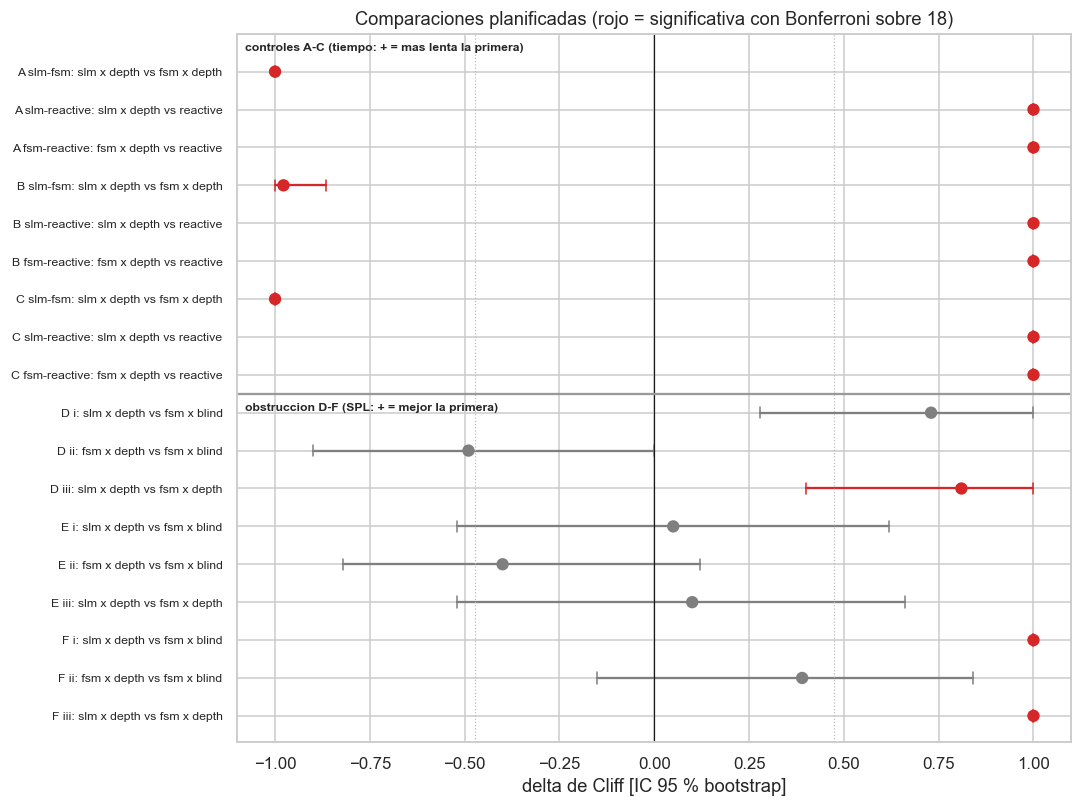

In [10]:
fig, ax = plt.subplots(figsize=(10, 7.5))
c = comps.reset_index(drop=True)
y = np.arange(len(c))[::-1]
col = np.where(c['significativa'], '#d62728', '#7f7f7f')
for yi, lo_, hi_, cc in zip(y, c['cliff_lo'], c['cliff_hi'], col):
    ax.plot([lo_, hi_], [yi, yi], color=cc, lw=1.5)
    ax.plot([lo_, lo_], [yi - 0.15, yi + 0.15], color=cc, lw=1); ax.plot([hi_, hi_], [yi - 0.15, yi + 0.15], color=cc, lw=1)
ax.scatter(c['cliff'], y, c=col, s=50, zorder=3)
ax.set_yticks(y, [f"{r.lote} {r.comparacion}: {r.a} vs {r.b}" for r in c.itertuples()], fontsize=8)
ax.axvline(0, color='k', lw=0.8)
for v in (-0.474, 0.474):
    ax.axvline(v, color='#bbb', ls=':', lw=0.8)
ax.axhline(8.5, color='#999')
ax.text(-1.08, 17.55, 'controles A-C (tiempo: + = mas lenta la primera)', fontsize=8, weight='bold')
ax.text(-1.08, 8.05, 'obstruccion D-F (SPL: + = mejor la primera)', fontsize=8, weight='bold')
ax.set_ylim(-0.7, 18.0)
ax.set_xlim(-1.1, 1.1); ax.set_xlabel('delta de Cliff [IC 95 % bootstrap]')
ax.set_title('Comparaciones planificadas (rojo = significativa con Bonferroni sobre 18)')
plt.tight_layout(); fig.savefig(FIG / 'v4_forest_cliff.png', dpi=150); plt.show()

**Lectura (informe §11.3–§11.4).**

- **Controles.** Las nueve comparaciones son significativas y todas con |δ| ≈ 1. `reactive` es el más rápido en ruta libre, `slm` le sigue y la FSM es la más lenta. El orden `slm` < `fsm` se explica en buena parte por los dos defectos de la FSM documentados en §11.5.
- **Obstrucción.** Son significativas (iii) en D, y (i) y (iii) en F, todas a favor de `slm x depth`. En E (bloqueo frontal) no hay diferencia, y `slm` completa solo 5 de 10.
- **Sesgo.** Toda comparación contra la FSM está sesgada a favor de `slm` por esos defectos.

## §7 — Secundarias (sin corrección, rotuladas como tales)

- **Diferencia de tasas de éxito** con IC de Newcombe (método 10, combinando los IC de Wilson de cada celda) y prueba exacta de Fisher.
- **Distancia mínima** (DistMin): δ de Cliff y permutación exacta.

No entran en la familia de Bonferroni: son descriptivas.

In [11]:
display(comps[['lote', 'comparacion', 'a', 'b', 'exito_a', 'exito_b', 'dif_exito', 'dif_exito_lo', 'dif_exito_hi', 'p_fisher', 'cliff_dist_min', 'p_dist_min']]
        .round(3))

,lote,comparacion,a,b,exito_a,exito_b,dif_exito,dif_exito_lo,dif_exito_hi,p_fisher,cliff_dist_min,p_dist_min
0,A,slm-fsm,slm x depth,fsm x depth,10/10,10/10,0.0,-0.278,0.278,1.000,0.07,0.810
1,A,slm-reactive,slm x depth,reactive,10/10,10/10,0.0,-0.278,0.278,1.000,0.31,0.254
2,A,fsm-reactive,fsm x depth,reactive,10/10,10/10,0.0,-0.278,0.278,1.000,0.13,0.643
3,B,slm-fsm,slm x depth,fsm x depth,10/10,9/10,0.1,-0.189,0.404,1.000,0.90,0.000
4,B,slm-reactive,slm x depth,reactive,10/10,10/10,0.0,-0.278,0.278,1.000,0.07,0.810
5,B,fsm-reactive,fsm x depth,reactive,9/10,10/10,-0.1,-0.404,0.189,1.000,-0.82,0.001
6,C,slm-fsm,slm x depth,fsm x depth,9/10,6/10,0.3,-0.082,0.599,0.303,0.94,0.000
7,C,slm-reactive,slm x depth,reactive,9/10,10/10,-0.1,-0.404,0.189,1.000,0.30,0.280
8,C,fsm-reactive,fsm x depth,reactive,6/10,10/10,-0.4,-0.687,-0.038,0.087,-1.00,0.000
9,D,i,slm x depth,fsm x blind,9/10,9/10,0.0,-0.315,0.315,1.000,-0.01,0.985


## §8 — H2: el costo de la arquitectura frente a la longitud de la ruta

La hipótesis H2 predice que el sobrecosto en tiempo del brazo `slm` frente al control reactivo **se diluye** con rutas más largas. Con las medianas del tiempo de misión exitosa en los tres controles:

celda,slm x depth,fsm x depth,reactive,L_opt (m),t_slm / t_reactive,t_fsm / t_reactive
lote,,,,,,
A,165.07,306.40,84.85,120,1.95,3.61
C,286.24,705.94,192.28,345,1.49,3.67
B,379.77,488.62,272.60,588,1.39,1.79


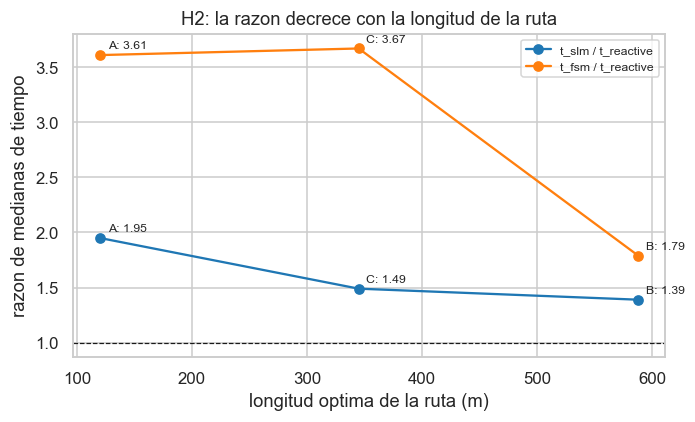

In [12]:
med = cells[cells['lote'].isin(['A', 'B', 'C'])].copy()
med['mediana_t'] = med['tiempo_exito_s'].str.split(' ').str[0].astype(float)
tab = med.pivot(index='lote', columns='celda', values='mediana_t')[['slm x depth', 'fsm x depth', 'reactive']]
tab['L_opt (m)'] = [round(L_opt[NOMBRE_LOTE[l]]) for l in tab.index]
tab['t_slm / t_reactive'] = (tab['slm x depth'] / tab['reactive']).round(2)
tab['t_fsm / t_reactive'] = (tab['fsm x depth'] / tab['reactive']).round(2)
tab = tab.sort_values('L_opt (m)')
display(tab)
fig, ax = plt.subplots(figsize=(6.5, 4))
for colname, c in (('t_slm / t_reactive', PALETA['slm x depth']), ('t_fsm / t_reactive', PALETA['fsm x depth'])):
    ax.plot(tab['L_opt (m)'], tab[colname], 'o-', color=c, label=colname)
    for l, x, yv in zip(tab.index, tab['L_opt (m)'], tab[colname]):
        ax.annotate(f'{l}: {yv:.2f}', (x, yv), xytext=(5, 4), textcoords='offset points', fontsize=8)
ax.axhline(1, color='k', ls='--', lw=0.8); ax.set_xlabel('longitud optima de la ruta (m)'); ax.set_ylabel('razon de medianas de tiempo')
ax.legend(fontsize=8); ax.set_title('H2: la razon decrece con la longitud de la ruta')
plt.tight_layout(); fig.savefig(FIG / 'v4_h2_razon.png', dpi=150); plt.show()

La razón `slm`/`reactive` baja de 1.95 a 1.39 a medida que la ruta se alarga: la predicción de H2 se cumple. El mecanismo postulado, en cambio, no: en la v4 la consulta estratégica no bloquea el lazo (§9), y el costo lo ponen lo que el brazo hace con las respuestas (sub-metas y maniobras) y el gobernador de velocidad. Con un solo escenario por *tier* y controles que difieren en más que la longitud, la forma aditiva es descriptiva (informe §11.7).

## §9 — Ritmo del lazo y latencias por celda (§11.6)

Desde los CSV de las 210 corridas, con todos los ciclos de las 10 corridas de cada celda juntos (la agregación del informe): período mediano entre ciclos, latencia del grafo (mediana y p95) y latencia mediana de la capa lenta. En `slm x depth` es la capa estratégica (una imagen por consulta). En `fsm x depth` son las consultas del barrido de deadlock con varias imágenes, porque la FSM no tiene capa estratégica. La figura muestra la dispersión entre corridas.

D:\TesisMCD\airsimenv\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
D:\TesisMCD\airsimenv\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
D:\TesisMCD\airsimenv\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
D:\TesisMCD\airsimenv\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
D:\TesisMCD\airsimenv\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
D:\TesisMCD\airsimenv\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, ou

ciclos  periodo_med_s  lat_med_ms  lat_p95_ms  lazo_lento_med_ms
lote celda                                                                        
A    fsm x depth   16019          0.204     109.810     230.747             466.45
     reactive       3895          0.207     163.289     273.990                NaN
     slm x depth    7668          0.207     136.799     257.958             111.80
B    fsm x depth   20336          0.228     216.511     316.485             968.60
     reactive      11488          0.232     224.999     308.682                NaN
     slm x depth   15817          0.231     216.046     322.452             125.00
C    fsm x depth   31233          0.221     172.807     299.872             435.75
     reactive       7555          0.244     236.581     332.215                NaN
     slm x depth   12124          0.232     211.068     310.064             104.00
D    fsm x blind   25184          0.229     213.796     318.949                NaN
     fsm x depth   30401          0.234     220.862     324.896             455.90
     reactive      39769          0.307     303.371     364.149                NaN
     slm x depth   19846          0.239     222.847     348.549             114.20
E    fsm x blind   20663          0.237     224.853     338.921                NaN
     fsm x depth   24986          0.232     217.759     325.359             457.50
     reactive      45576          0.258     254.832     325.464                NaN
     slm x depth   17088          0.238     221.638     335.703             114.20
F    fsm x blind   31221          0.239     218.506     334.351                NaN
     fsm x depth   30817          0.233     201.517     332.860             585.10
     reactive      12034          0.258     247.496     353.537                NaN
     slm x depth   19598          0.238     188.723     343.694             134.40

periodo mediano por celda: 0.20-0.31 s; latencia mediana 110-303 ms; p95 231-364 ms; capa estrategica (slm) 104-134 ms


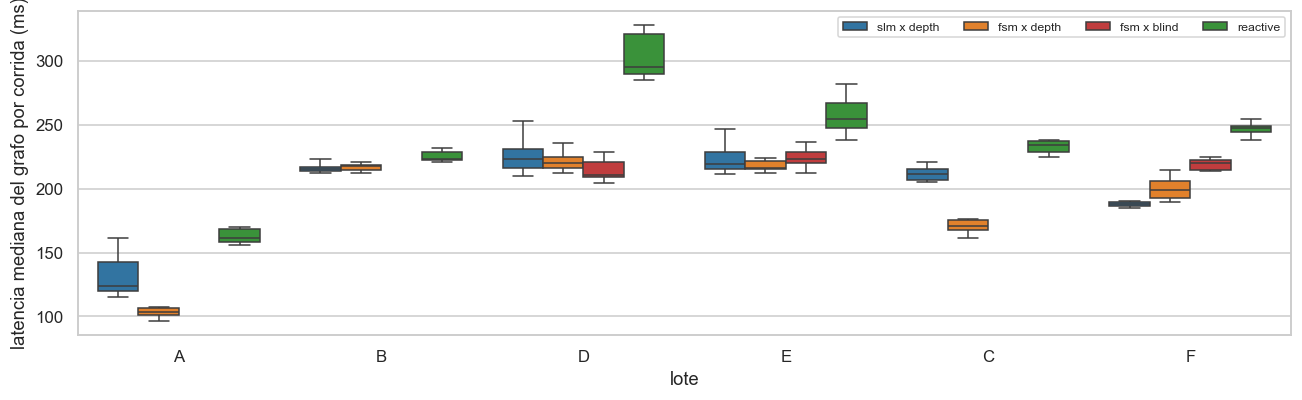

In [13]:
ciclos, por_corrida = collections.defaultdict(list), []
for r in kept:
    p = V4 / r['_path']
    csvp = p.with_name(p.name.replace('.summary.json', '.csv'))
    d = pd.read_csv(csvp, usecols=['t', 'latency_graph_ms', 'slm_latency_ms'], low_memory=False)
    d['periodo_s'] = d['t'].diff()
    d['slm_latency_ms'] = pd.to_numeric(d['slm_latency_ms'], errors='coerce')
    key = (AL.LOTES[r['scenario']], AL.cell_label(r))
    ciclos[key].append(d)
    por_corrida.append({'lote': key[0], 'celda': key[1], 'lat_med_ms': d['latency_graph_ms'].median()})
# Agregacion del informe: todos los ciclos de las 10 corridas de la celda juntos
filas = []
for (lote, celda), ds in sorted(ciclos.items()):
    d = pd.concat(ds)
    filas.append({'lote': lote, 'celda': celda, 'ciclos': len(d), 'periodo_med_s': d['periodo_s'].median(),
                  'lat_med_ms': d['latency_graph_ms'].median(), 'lat_p95_ms': d['latency_graph_ms'].quantile(.95),
                  'lazo_lento_med_ms': d['slm_latency_ms'].median()})
tab_lat = pd.DataFrame(filas).set_index(['lote', 'celda']).round(3)
display(tab_lat)
print(f"periodo mediano por celda: {tab_lat['periodo_med_s'].min():.2f}-{tab_lat['periodo_med_s'].max():.2f} s; "
      f"latencia mediana {tab_lat['lat_med_ms'].min():.0f}-{tab_lat['lat_med_ms'].max():.0f} ms; "
      f"p95 {tab_lat['lat_p95_ms'].min():.0f}-{tab_lat['lat_p95_ms'].max():.0f} ms; "
      f"capa estrategica (slm) {tab_lat.xs('slm x depth', level='celda')['lazo_lento_med_ms'].min():.0f}-"
      f"{tab_lat.xs('slm x depth', level='celda')['lazo_lento_med_ms'].max():.0f} ms")
lat = pd.DataFrame(por_corrida)
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.boxplot(data=lat, x='lote', y='lat_med_ms', hue='celda', hue_order=CELDAS, palette=PALETA, ax=ax, showfliers=False)
ax.set_ylabel('latencia mediana del grafo por corrida (ms)'); ax.legend(fontsize=8, ncol=4)
plt.tight_layout(); fig.savefig(FIG / 'v4_latencias.png', dpi=150); plt.show()

## §10 — Verificación contra el reporte y exportación

Se comparan las tablas de este cuaderno con los CSV que escribió `analyze_lotes.py --family 18` en `v4/`. El *bootstrap* usa semilla fija, así que los IC coinciden exactamente.

In [14]:
ref_cells = pd.read_csv(V4 / 'analisis_lotes_celdas.csv')
ref_comps = pd.read_csv(V4 / 'analisis_lotes_comparaciones.csv')
k1 = ['lote', 'celda']; k2 = ['lote', 'comparacion']
m1 = cells.merge(ref_cells, on=k1, suffixes=('', '_ref'))
m2 = comps.merge(ref_comps, on=k2, suffixes=('', '_ref'))
chk = {
    'celdas: n y exitos': bool((m1['n'] == m1['n_ref']).all() and (m1['exitos'] == m1['exitos_ref']).all()),
    'celdas: SPL, tiempo y DistMin (texto)': bool((m1['spl'] == m1['spl_ref']).all() and (m1['tiempo_exito_s'] == m1['tiempo_exito_s_ref']).all()
                                                  and (m1['dist_min_m'] == m1['dist_min_m_ref']).all()),
    'comparaciones: delta de Cliff e IC': bool(np.allclose(m2[['cliff', 'cliff_lo', 'cliff_hi']].values, m2[['cliff_ref', 'cliff_lo_ref', 'cliff_hi_ref']].values)),
    'comparaciones: p y p Bonferroni': bool(np.allclose(m2[['p', 'p_bonf']].values, m2[['p_ref', 'p_bonf_ref']].values)),
    'comparaciones: significancia': bool((m2['significativa'] == m2['significativa_ref']).all()),
    'filas': (len(m1), len(ref_cells), len(m2), len(ref_comps)),
}
for k, v in chk.items():
    print(f'{k:<45} {v}')
assert all(v for k, v in chk.items() if k != 'filas'), 'el cuaderno no reproduce analisis_lotes.md'

cells.to_csv(OUT / 'v4_celdas.csv', index=False)
comps.to_csv(OUT / 'v4_comparaciones.csv', index=False)
tab.to_csv(OUT / 'v4_h2_razon.csv')
tab_lat.to_csv(OUT / 'v4_latencias.csv')
print('\nexportado en', OUT.relative_to(ROOT), ':', sorted(p.name for p in OUT.glob('v4_*.csv')))
print('figuras:', sorted(p.name for p in FIG.glob('v4_*.png')))

celdas: n y exitos                            True
celdas: SPL, tiempo y DistMin (texto)         True
comparaciones: delta de Cliff e IC            True
comparaciones: p y p Bonferroni               True
comparaciones: significancia                  True
filas                                         (21, 21, 18, 18)

exportado en airsim-loop\notebooks\output : ['v4_celdas.csv', 'v4_comparaciones.csv', 'v4_h2_razon.csv', 'v4_latencias.csv']
figuras: ['v4_exito_wilson.png', 'v4_forest_cliff.png', 'v4_h2_razon.png', 'v4_latencias.png', 'v4_metrica_primaria.png']
